# Parallel Execution in LangGraph: From Sequential to Concurrent Workflows

## Tutorial Overview

In this tutorial, you'll learn how to transform a sequential agentic workflow into a highly efficient parallel execution system using **LangGraph's parallelization patterns**. We'll explore two distinct approaches:

1. **AsyncIO Gather Method**: Using Python's native async/await patterns
2. **Send API Method**: Using LangGraph's purpose-built parallelization primitives

## Learning Objectives

By the end of this tutorial, you will be able to:

1. Identify bottlenecks in sequential workflows that can benefit from parallelization
2. Implement parallel execution using Python's `asyncio.gather()` pattern
3. Implement parallel execution using LangGraph's `Send` API
4. Compare and contrast both approaches to choose the right one for your use case
5. Measure and analyze performance improvements from parallelization
6. Understand when parallelization provides real benefits vs. added complexity

## The Problem: Sequential Verification is Slow

In our fact-checking workflow from the previous tutorial, we have a critical bottleneck:

```python
# Current approach: Sequential verification
for claim in claims:
    result = verification_subgraph.invoke(claim)  # Wait for each one
    results.append(result)
```

**The problem**: If we have 3 claims, and each verification takes 15 seconds:
- Sequential execution: **45 seconds** total
- Parallel execution: **~15 seconds** total (all three happen simultaneously)

This is a massive time saving, especially as the number of claims grows!

## Why Parallel Execution Matters

Modern agentic workflows often involve:
- **I/O-bound operations**: API calls, web searches, database queries
- **Independent tasks**: Verifying claims that don't depend on each other
- **User experience**: Reducing latency improves perceived responsiveness
- **Cost efficiency**: Less total execution time means lower computational costs

## What You'll Build

We'll take the fact-checking system from Tutorial 4.5 and create two parallel versions:

**Approach 1 - AsyncIO Gather**:
```
verify_claims_node:
  ├─ async gather all claims
  ├─ verification_subgraph(claim1)  ┐
  ├─ verification_subgraph(claim2)  ├─ All happen simultaneously
  └─ verification_subgraph(claim3)  ┘
```

**Approach 2 - Send API**:
```
route_to_verify → verify_claim1 ┐
                → verify_claim2 ├─ Parallel branches
                → verify_claim3 ┘
                         ↓
                  aggregate_results
```

## Prerequisites

- Completion of Tutorial 4.5 (Subgraphs - Fact Checker)
- Understanding of async/await in Python (helpful but not required)
- API keys for OpenAI and Tavily

## Part 1: Why Parallel Execution?

### The Sequential Bottleneck

Let's understand the problem we're solving. In our fact-checker workflow:

1. **Extract Claims**: Takes ~5 seconds (LLM call to identify claims)
2. **Verify Claims**: Takes ~15 seconds **per claim** (web search + LLM analysis)
3. **Generate Report**: Takes ~3 seconds (LLM call to create report)

For 3 claims:
- **Sequential**: 5 + (15 × 3) + 3 = **53 seconds**
- **Parallel**: 5 + 15 + 3 = **23 seconds** (56% time savings!)

### When to Use Parallel Execution

Parallelization provides benefits when:
- **Tasks are independent**: One claim's verification doesn't affect another
- **Tasks are I/O-bound**: Waiting for API responses, not CPU computation
- **Multiple items to process**: Lists, batches, collections of similar tasks
- **Time constraints**: User-facing applications where latency matters

### Two Approaches to Parallelization

**1. AsyncIO Gather**: Use Python's native async capabilities
- **Pros**: Simple, familiar Python patterns, low overhead
- **Cons**: All parallelism hidden in one node, less visibility

**2. Send API**: Use LangGraph's built-in parallelization
- **Pros**: Explicit graph structure, LangGraph manages state, better observability
- **Cons**: More complex setup, LangGraph-specific patterns

Let's implement both and compare!

## Part 2: Environment Setup

Let's set up our environment with all necessary dependencies.

In [1]:
# Install required packages
# Uncomment the following line if you need to install the packages
# !pip install langgraph langchain langchain-openai python-dotenv tavily-python

In [2]:
# Load environment variables
from dotenv import load_dotenv
import os

# Load API keys from .env file
load_dotenv()

# Verify that keys are loaded
assert os.getenv("OPENAI_API_KEY"), "OPENAI_API_KEY not found in environment"
assert os.getenv("TAVILY_API_KEY"), "TAVILY_API_KEY not found in environment"

print("Environment variables loaded successfully!")

Environment variables loaded successfully!


## Part 3: Import Dependencies

Note the new imports for parallel execution:
- `asyncio`: For async/await parallelization
- `Send` from `langgraph.types`: For LangGraph's Send API
- `time`: For performance measurement

In [3]:
from typing import TypedDict, List, Dict, Any, Annotated
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send  # NEW: For parallel execution with Send API
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage, SystemMessage
from pydantic import BaseModel, Field
from tavily import TavilyClient
import json
import asyncio  # NEW: For async/await parallelization
import time  # NEW: For performance measurement
from operator import add

print("All imports successful!")

All imports successful!


## Part 4: Initialize Tools and LLM

Same setup as before - we're not changing how individual tools work, just how we orchestrate them.

In [4]:
# Initialize the language model
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

# Initialize Tavily client for web search
tavily_client = TavilyClient(api_key=os.getenv("TAVILY_API_KEY"))

# Create a search tool function
def internet_search(query: str, max_results: int = 5) -> dict:
    """
    Search the web for information using Tavily.
    
    Args:
        query: The search query string
        max_results: Maximum number of results to return (default: 5)
    
    Returns:
        Dictionary containing search results with titles, URLs, and content
    """
    try:
        results = tavily_client.search(query, max_results=max_results)
        return results
    except Exception as e:
        return {"error": f"Search failed: {str(e)}"}

print("Tavily search tool configured successfully!")
print("LLM and tools initialized!")

Tavily search tool configured successfully!
LLM and tools initialized!


## Part 5: Define State Schemas

We'll use the same state schemas as before, with one modification to the main state for parallel execution.

In [5]:
# Pydantic models for structured outputs

class Claim(BaseModel):
    """A single factual claim extracted from an article."""
    claim_text: str = Field(description="The specific factual claim")
    verifiability_score: float = Field(description="Score 0-1 indicating how verifiable this claim is")
    context: str = Field(description="Relevant context from the article")

class ClaimList(BaseModel):
    """List of claims extracted from an article."""
    claims: List[Claim] = Field(description="List of extracted claims")

class SourceQuality(BaseModel):
    """Quality assessment of a source."""
    credibility_score: float = Field(description="Score 0-1 for source credibility")
    freshness_score: float = Field(description="Score 0-1 for information freshness")
    relevance_score: float = Field(description="Score 0-1 for relevance to claim")
    reasoning: str = Field(description="Explanation of the scores")

class VerificationResult(BaseModel):
    """Result of verifying a single claim."""
    claim: str = Field(description="The claim that was verified")
    verdict: str = Field(description="TRUE, FALSE, PARTIALLY_TRUE, or UNVERIFIABLE")
    confidence: float = Field(description="Confidence score 0-1")
    evidence: str = Field(description="Supporting evidence and reasoning")
    sources: List[str] = Field(description="URLs of sources used")

# State schemas for different graph levels

class MainWorkflowState(TypedDict):
    """State for the main fact-checking workflow."""
    article: str
    claims: List[Dict[str, Any]]
    # NEW: Using Annotated with add operator to accumulate results from parallel executions
    verification_results: Annotated[List[Dict[str, Any]], add]
    final_report: str

class ClaimExtractionState(TypedDict):
    """State for claim extraction subgraph."""
    article: str
    raw_claims: str
    ranked_claims: List[Dict[str, Any]]

class VerificationState(TypedDict):
    """State for verification subgraph."""
    claim: str
    search_results: List[Dict[str, Any]]
    source_quality_assessments: List[Dict[str, Any]]
    verification_result: Dict[str, Any]

class SourceQualityState(TypedDict):
    """State for source quality subgraph."""
    source_url: str
    source_content: str
    claim: str
    quality_assessment: Dict[str, Any]

print("State schemas defined!")
print("\nKey modification for parallel execution:")
print("  verification_results uses Annotated[List, add] to accumulate parallel results")

State schemas defined!

Key modification for parallel execution:
  verification_results uses Annotated[List, add] to accumulate parallel results


## Part 6: Build the Subgraphs (Unchanged)

These subgraphs remain exactly the same - we're not changing how they work internally, just how we invoke them.

### Claim Extraction Subgraph

In [6]:
# Node 1: Extract raw claims from article
def extract_claims_node(state: ClaimExtractionState) -> ClaimExtractionState:
    """
    Analyzes the article and extracts factual claims using structured output.
    """
    article = state["article"]
    
    print("Extracting claims from article...")
    
    system_prompt = """You are a fact-checking expert that extracts verifiable claims from news articles.
    
Analyze the article and identify specific factual claims that can be verified.
Focus on:
- Statistical claims (numbers, percentages, dates)
- Claims about events that happened
- Statements about people, places, or organizations
- Cause-and-effect relationships

Avoid:
- Opinions or subjective statements
- Vague or ambiguous claims
- Claims that are definitional or tautological

For each claim, assess its verifiability (0-1 score):
- 1.0: Highly verifiable (specific, concrete, with clear metrics)
- 0.5: Moderately verifiable (some specificity, but may require interpretation)
- 0.0: Not verifiable (too vague, subjective, or opinion-based)
"""
    
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": f"Article:\n{article}"}
    ]
    
    # Use structured output
    claim_extractor = llm.with_structured_output(ClaimList)
    result = claim_extractor.invoke(messages)
    
    print(f"Extracted {len(result.claims)} claims")
    
    return {**state, "raw_claims": str(result.model_dump())}

# Node 2: Rank claims by verifiability
def rank_claims_node(state: ClaimExtractionState) -> ClaimExtractionState:
    """
    Ranks extracted claims by verifiability score.
    """
    raw_claims = eval(state["raw_claims"])  # Convert string back to dict
    claims_list = raw_claims["claims"]
    
    print("Ranking claims by verifiability...")
    
    # Sort claims by verifiability score (highest first)
    ranked = sorted(claims_list, key=lambda x: x["verifiability_score"], reverse=True)
    
    # Take top 3 most verifiable claims
    top_claims = ranked[:3]
    
    print(f"Selected top {len(top_claims)} claims for verification")
    for i, claim in enumerate(top_claims, 1):
        print(f"  {i}. [{claim['verifiability_score']:.2f}] {claim['claim_text'][:80]}...")
    
    return {**state, "ranked_claims": top_claims}

# Build the claim extraction subgraph
claim_extraction_builder = StateGraph(ClaimExtractionState)
claim_extraction_builder.add_node("extract_claims", extract_claims_node)
claim_extraction_builder.add_node("rank_claims", rank_claims_node)
claim_extraction_builder.add_edge(START, "extract_claims")
claim_extraction_builder.add_edge("extract_claims", "rank_claims")
claim_extraction_builder.add_edge("rank_claims", END)
claim_extraction_subgraph = claim_extraction_builder.compile()

print("\nClaim Extraction Subgraph built!")


Claim Extraction Subgraph built!


### Source Quality Subgraph

In [7]:
def assess_source_quality_node(state: SourceQualityState) -> SourceQualityState:
    """
    Assesses the quality of a source for fact-checking purposes.
    """
    source_url = state["source_url"]
    source_content = state["source_content"]
    claim = state["claim"]
    
    print(f"Assessing source quality: {source_url[:60]}...")
    
    system_prompt = """You are a source quality assessor for fact-checking.

Evaluate the source on three dimensions:

1. Credibility (0-1):
   - Is this from a reputable organization?
   - Does it cite sources or provide evidence?
   - Is the author identified and credible?

2. Freshness (0-1):
   - Is the information recent and up-to-date?
   - Is it relevant to the current context?

3. Relevance (0-1):
   - How directly does this source address the claim?
   - Does it provide specific evidence for or against the claim?
"""
    
    user_prompt = f"""Claim: {claim}

Source URL: {source_url}

Source Content:
{source_content[:1000]}...

Assess the quality of this source for verifying the claim."""
    
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": user_prompt}
    ]
    
    # Use structured output
    quality_assessor = llm.with_structured_output(SourceQuality)
    result = quality_assessor.invoke(messages)
    
    print(f"  Credibility: {result.credibility_score:.2f}, Freshness: {result.freshness_score:.2f}, Relevance: {result.relevance_score:.2f}")
    
    return {**state, "quality_assessment": result.model_dump()}

# Build the source quality subgraph
source_quality_builder = StateGraph(SourceQualityState)
source_quality_builder.add_node("assess_quality", assess_source_quality_node)
source_quality_builder.add_edge(START, "assess_quality")
source_quality_builder.add_edge("assess_quality", END)
source_quality_subgraph = source_quality_builder.compile()

print("\nSource Quality Subgraph built!")


Source Quality Subgraph built!


### Verification Subgraph

In [8]:
# Node 1: Search for sources
def search_sources_node(state: VerificationState) -> VerificationState:
    """
    Searches the web for sources related to the claim.
    """
    claim = state["claim"]
    
    print(f"  Searching for sources to verify: {claim[:80]}...")
    
    # Perform web search
    search_results = internet_search(claim, max_results=3)
    
    if "error" in search_results:
        print(f"  Search error: {search_results['error']}")
        return {**state, "search_results": []}
    
    results = search_results.get("results", [])
    print(f"  Found {len(results)} sources")
    
    return {**state, "search_results": results}

# Node 2: Assess source quality (calls source quality subgraph)
def assess_sources_node(state: VerificationState) -> VerificationState:
    """
    Assesses the quality of each source by invoking the source quality subgraph.
    """
    claim = state["claim"]
    search_results = state["search_results"]
    
    print("  Assessing source quality...")
    
    quality_assessments = []
    
    for result in search_results:
        # Invoke the source quality subgraph for each source
        subgraph_input = {
            "source_url": result.get("url", ""),
            "source_content": result.get("content", ""),
            "claim": claim,
            "quality_assessment": {}
        }
        
        subgraph_output = source_quality_subgraph.invoke(subgraph_input)
        
        quality_assessments.append({
            "url": result.get("url", ""),
            "quality": subgraph_output["quality_assessment"]
        })
    
    return {**state, "source_quality_assessments": quality_assessments}

# Node 3: Generate verification result
def generate_verdict_node(state: VerificationState) -> VerificationState:
    """
    Generates the final verification verdict based on sources and quality assessments.
    """
    claim = state["claim"]
    search_results = state["search_results"]
    quality_assessments = state["source_quality_assessments"]
    
    print("  Generating verification verdict...")
    
    # Prepare context with sources and quality scores
    sources_context = ""
    for i, (result, quality) in enumerate(zip(search_results, quality_assessments), 1):
        sources_context += f"\n\nSource {i}:\n"
        sources_context += f"URL: {result.get('url', 'N/A')}\n"
        sources_context += f"Content: {result.get('content', '')[:500]}...\n"
        sources_context += f"Quality Scores - Credibility: {quality['quality']['credibility_score']:.2f}, "
        sources_context += f"Freshness: {quality['quality']['freshness_score']:.2f}, "
        sources_context += f"Relevance: {quality['quality']['relevance_score']:.2f}\n"
    
    system_prompt = """You are a fact-checking expert that verifies claims based on source evidence.

Analyze the sources and their quality scores to determine:

Verdict:
- TRUE: The claim is supported by high-quality sources
- FALSE: The claim is contradicted by high-quality sources
- PARTIALLY_TRUE: Some aspects are true, others are not
- UNVERIFIABLE: Insufficient or conflicting evidence

Confidence (0-1):
- Consider source quality scores
- Higher confidence when multiple high-quality sources agree
- Lower confidence when sources conflict or quality is poor

Provide clear evidence and reasoning.
"""
    
    user_prompt = f"""Claim to verify: {claim}

Available sources:
{sources_context}

Verify this claim and provide your verdict."""
    
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": user_prompt}
    ]
    
    # Use structured output
    verifier = llm.with_structured_output(VerificationResult)
    result = verifier.invoke(messages)
    
    print(f"  Verdict: {result.verdict} (confidence: {result.confidence:.2f})")
    
    return {**state, "verification_result": result.model_dump()}

# Build the verification subgraph
verification_builder = StateGraph(VerificationState)
verification_builder.add_node("search_sources", search_sources_node)
verification_builder.add_node("assess_sources", assess_sources_node)
verification_builder.add_node("generate_verdict", generate_verdict_node)
verification_builder.add_edge(START, "search_sources")
verification_builder.add_edge("search_sources", "assess_sources")
verification_builder.add_edge("assess_sources", "generate_verdict")
verification_builder.add_edge("generate_verdict", END)
verification_subgraph = verification_builder.compile()

print("\nVerification Subgraph built!")


Verification Subgraph built!


## Part 7: Approach 1 - Parallel Execution with AsyncIO Gather

### The AsyncIO Pattern

This approach uses Python's native `asyncio.gather()` to run multiple async operations concurrently.

**Key concepts**:
- `async def`: Defines an asynchronous function
- `await`: Pauses execution until an async operation completes
- `asyncio.gather()`: Runs multiple async operations concurrently
- `ainvoke()`: LangGraph's async version of `invoke()`

**How it works**:
1. Create async tasks for each claim verification
2. Use `asyncio.gather()` to execute all tasks simultaneously
3. Collect results when all tasks complete
4. All parallelism happens within a single node

**Advantages**:
- Simple to implement if you're familiar with async Python
- Low overhead - just uses Python's built-in async capabilities
- Clean graph structure - parallelism is hidden in the implementation

**Disadvantages**:
- Less visibility into what's happening during execution
- Manual result aggregation
- Requires understanding of async/await patterns

In [9]:
# Node 1: Extract claims (same as before)
def extract_claims_async(state: MainWorkflowState) -> MainWorkflowState:
    """
    Extracts claims from the article by invoking the claim extraction subgraph.
    """
    article = state["article"]
    
    print("="*80)
    print("STEP 1: EXTRACTING CLAIMS")
    print("="*80)
    
    subgraph_input = {
        "article": article,
        "raw_claims": "",
        "ranked_claims": []
    }
    
    subgraph_output = claim_extraction_subgraph.invoke(subgraph_input)
    claims = subgraph_output["ranked_claims"]
    
    return {**state, "claims": claims}

# Node 2: Verify all claims in parallel using asyncio.gather()
async def verify_claims_async_gather(state: MainWorkflowState) -> MainWorkflowState:
    """
    Verifies all claims in parallel using asyncio.gather().
    This approach keeps all parallelism within a single node.
    """
    claims = state["claims"]
    
    print("\n" + "="*80)
    print("STEP 2: VERIFYING CLAIMS IN PARALLEL (AsyncIO Gather)")
    print("="*80)
    print(f"Verifying {len(claims)} claims concurrently using asyncio.gather()...\n")
    
    start_time = time.time()
    
    # Create async tasks for each claim verification
    async def verify_single_claim(claim_obj, index):
        """
        Async function to verify a single claim.
        """
        print(f"[Claim {index}] Starting verification: {claim_obj['claim_text'][:60]}...")
        
        subgraph_input = {
            "claim": claim_obj["claim_text"],
            "search_results": [],
            "source_quality_assessments": [],
            "verification_result": {}
        }
        
        # Use ainvoke() for async execution
        result = await verification_subgraph.ainvoke(subgraph_input)
        
        print(f"[Claim {index}] Completed verification")
        return result["verification_result"]
    
    # Execute all verifications in parallel using gather
    verification_results = await asyncio.gather(
        *[verify_single_claim(claim, i+1) for i, claim in enumerate(claims)]
    )
    
    end_time = time.time()
    elapsed = end_time - start_time
    
    print(f"\nAll {len(claims)} claims verified in {elapsed:.2f} seconds (parallel execution)")
    print(f"Estimated sequential time: ~{len(claims) * 15:.0f} seconds")
    print(f"Time saved: ~{(len(claims) * 15) - elapsed:.0f} seconds ({(1 - elapsed / (len(claims) * 15)) * 100:.1f}% reduction)\n")
    
    return {**state, "verification_results": verification_results}

# Node 3: Generate report (same as before)
def generate_report_async(state: MainWorkflowState) -> MainWorkflowState:
    """
    Generates a comprehensive fact-checking report.
    """
    verification_results = state["verification_results"]
    
    print("="*80)
    print("STEP 3: GENERATING REPORT")
    print("="*80)
    
    system_prompt = """You are a fact-checking report writer.

Create a clear, professional fact-checking report that:
- Summarizes the verification results
- Explains the evidence for each claim
- Provides an overall assessment
- Uses clear formatting with sections and bullet points
"""
    
    user_prompt = f"""Generate a fact-checking report for these verification results:

{json.dumps(verification_results, indent=2)}

Create a comprehensive report."""
    
    messages = [
        SystemMessage(content=system_prompt),
        HumanMessage(content=user_prompt)
    ]
    
    response = llm.invoke(messages)
    print("Report generated!\n")
    
    return {**state, "final_report": response.content}

# Build the main workflow with AsyncIO approach
asyncio_workflow_builder = StateGraph(MainWorkflowState)
asyncio_workflow_builder.add_node("extract_claims", extract_claims_async)
asyncio_workflow_builder.add_node("verify_claims", verify_claims_async_gather)
asyncio_workflow_builder.add_node("generate_report", generate_report_async)
asyncio_workflow_builder.add_edge(START, "extract_claims")
asyncio_workflow_builder.add_edge("extract_claims", "verify_claims")
asyncio_workflow_builder.add_edge("verify_claims", "generate_report")
asyncio_workflow_builder.add_edge("generate_report", END)
fact_checker_asyncio = asyncio_workflow_builder.compile()

print("\n" + "="*80)
print("ASYNCIO WORKFLOW BUILT!")
print("="*80)
print("\nArchitecture:")
print("  extract_claims → verify_claims (asyncio.gather) → generate_report")
print("\nParallel execution happens inside the verify_claims node using asyncio.gather()")


ASYNCIO WORKFLOW BUILT!

Architecture:
  extract_claims → verify_claims (asyncio.gather) → generate_report

Parallel execution happens inside the verify_claims node using asyncio.gather()


### Test the AsyncIO Approach

Let's test our parallel execution using asyncio.gather().

In [10]:
# Sample news article for testing
sample_article = """
Breaking News: Major AI Breakthrough Announced

SAN FRANCISCO - Tech giant OpenAI announced today that their latest AI model, GPT-5, 
has achieved human-level performance on over 95% of standardized tests. The company 
claims this represents a 300% improvement over their previous model.

According to CEO Sam Altman, the new model was trained on a dataset containing 
10 trillion tokens, making it the largest language model ever created. The training 
process reportedly cost over $500 million and required the computational power 
equivalent to 50,000 high-end GPUs running continuously for six months.

Industry experts predict that this breakthrough will lead to the automation of 
20 million jobs worldwide by the end of 2025. Dr. Sarah Chen, AI researcher at 
MIT, stated that "this technology will fundamentally transform every industry 
within the next two years."

The announcement caused OpenAI's valuation to surge by 40% to $200 billion, 
making it the most valuable AI company in the world.
"""

print("Testing AsyncIO parallel execution approach...")
print("\nArticle:")
print("-" * 80)
print(sample_article)
print("-" * 80)

Testing AsyncIO parallel execution approach...

Article:
--------------------------------------------------------------------------------

Breaking News: Major AI Breakthrough Announced

SAN FRANCISCO - Tech giant OpenAI announced today that their latest AI model, GPT-5, 
has achieved human-level performance on over 95% of standardized tests. The company 
claims this represents a 300% improvement over their previous model.

According to CEO Sam Altman, the new model was trained on a dataset containing 
10 trillion tokens, making it the largest language model ever created. The training 
process reportedly cost over $500 million and required the computational power 
equivalent to 50,000 high-end GPUs running continuously for six months.

Industry experts predict that this breakthrough will lead to the automation of 
20 million jobs worldwide by the end of 2025. Dr. Sarah Chen, AI researcher at 
MIT, stated that "this technology will fundamentally transform every industry 
within the next

In [11]:
# Run the fact-checker with AsyncIO approach
initial_state = {
    "article": sample_article,
    "claims": [],
    "verification_results": [],
    "final_report": ""
}

# Execute the workflow
result_asyncio = await fact_checker_asyncio.ainvoke(initial_state)

# Display the final report
print("\n" + "="*80)
print("FINAL FACT-CHECKING REPORT (AsyncIO Approach)")
print("="*80)
print(result_asyncio["final_report"])

STEP 1: EXTRACTING CLAIMS
Extracting claims from article...
Extracted 8 claims
Ranking claims by verifiability...
Selected top 3 claims for verification
  1. [1.00] OpenAI's latest AI model, GPT-5, has achieved human-level performance on over 95...
  2. [1.00] The new model represents a 300% improvement over the previous model....
  3. [1.00] The new model was trained on a dataset containing 10 trillion tokens....

STEP 2: VERIFYING CLAIMS IN PARALLEL (AsyncIO Gather)
Verifying 3 claims concurrently using asyncio.gather()...

[Claim 1] Starting verification: OpenAI's latest AI model, GPT-5, has achieved human-level pe...
[Claim 2] Starting verification: The new model represents a 300% improvement over the previou...
[Claim 3] Starting verification: The new model was trained on a dataset containing 10 trillio...
  Searching for sources to verify: OpenAI's latest AI model, GPT-5, has achieved human-level performance on over 95...
  Searching for sources to verify: The new model represent

## Part 8: Approach 2 - Parallel Execution with Send API

### The Send API Pattern

LangGraph's `Send` API is a purpose-built mechanism for dynamic parallel execution within graphs.

**Key concepts**:
- `Send`: A special object that tells LangGraph to invoke a node with specific data
- **Conditional edges**: Returns a list of `Send` objects to create parallel branches
- **State accumulation**: LangGraph automatically merges results from parallel branches
- **Graph visualization**: Each parallel execution is visible in the graph

**How it works**:
1. Router node returns a list of `Send` objects (one per claim)
2. LangGraph creates parallel node invocations
3. Each node processes independently
4. Results are automatically accumulated in state
5. Aggregation node waits for all parallel tasks to complete

**Advantages**:
- Explicit in graph structure - you can see parallel branches
- LangGraph handles state management automatically
- Better observability and debugging
- Natural fit for LangGraph workflows

**Disadvantages**:
- More complex graph setup
- LangGraph-specific pattern (not standard Python)
- Requires understanding of Send mechanics

In [12]:
# Node 1: Extract claims (same as before)
def extract_claims_send(state: MainWorkflowState) -> MainWorkflowState:
    """
    Extracts claims from the article by invoking the claim extraction subgraph.
    """
    article = state["article"]
    
    print("="*80)
    print("STEP 1: EXTRACTING CLAIMS")
    print("="*80)
    
    subgraph_input = {
        "article": article,
        "raw_claims": "",
        "ranked_claims": []
    }
    
    subgraph_output = claim_extraction_subgraph.invoke(subgraph_input)
    claims = subgraph_output["ranked_claims"]
    
    return {**state, "claims": claims}

# Router: Creates Send objects for parallel verification
def route_to_verify(state: MainWorkflowState):
    """
    Router that creates parallel Send commands for each claim.
    Each Send will invoke the verify_single_claim node.
    
    This is the key to parallel execution with Send API:
    - Returning a list of Send objects tells LangGraph to execute them in parallel
    - Each Send specifies the node to invoke and the data to send
    - LangGraph handles the parallelization automatically
    """
    claims = state["claims"]
    
    print("\n" + "="*80)
    print("STEP 2: ROUTING CLAIMS FOR PARALLEL VERIFICATION (Send API)")
    print("="*80)
    print(f"Creating {len(claims)} parallel Send operations...\n")
    
    # Create a Send object for each claim
    # Each Send will invoke verify_single_claim with the claim data
    return [
        Send("verify_single_claim", {"claim": claim, "index": i+1})
        for i, claim in enumerate(claims)
    ]

# Node 2: Verify a single claim (will be invoked multiple times in parallel)
def verify_single_claim_node(claim_data: dict) -> dict:
    """
    Processes a single claim verification.
    This node will be invoked multiple times in parallel by Send.
    
    Each parallel invocation is independent and processes one claim.
    """
    claim_obj = claim_data["claim"]
    index = claim_data["index"]
    
    print(f"[Claim {index}] Starting verification: {claim_obj['claim_text'][:60]}...")
    
    subgraph_input = {
        "claim": claim_obj["claim_text"],
        "search_results": [],
        "source_quality_assessments": [],
        "verification_result": {}
    }
    
    result = verification_subgraph.invoke(subgraph_input)
    
    print(f"[Claim {index}] Completed verification")
    
    # Return results that will be accumulated in verification_results
    # The Annotated[List, add] in state schema handles accumulation
    return {"verification_results": [result["verification_result"]]}

# Node 3: Aggregate results
def aggregate_results(state: MainWorkflowState) -> MainWorkflowState:
    """
    Aggregates all parallel verification results.
    
    Note: Due to Annotated[List, add] in the state schema,
    LangGraph automatically accumulates results from parallel branches.
    This node just marks the completion of parallel processing.
    """
    verification_results = state["verification_results"]
    
    print(f"\nAll {len(verification_results)} claims verified (parallel execution complete)")
    print("Results automatically aggregated by LangGraph\n")
    
    return state

# Node 4: Generate report (same as before)
def generate_report_send(state: MainWorkflowState) -> MainWorkflowState:
    """
    Generates a comprehensive fact-checking report.
    """
    verification_results = state["verification_results"]
    
    print("="*80)
    print("STEP 3: GENERATING REPORT")
    print("="*80)
    
    system_prompt = """You are a fact-checking report writer.

Create a clear, professional fact-checking report that:
- Summarizes the verification results
- Explains the evidence for each claim
- Provides an overall assessment
- Uses clear formatting with sections and bullet points
"""
    
    user_prompt = f"""Generate a fact-checking report for these verification results:

{json.dumps(verification_results, indent=2)}

Create a comprehensive report."""
    
    messages = [
        SystemMessage(content=system_prompt),
        HumanMessage(content=user_prompt)
    ]
    
    response = llm.invoke(messages)
    print("Report generated!\n")
    
    return {**state, "final_report": response.content}

# Build the main workflow with Send API approach
send_workflow_builder = StateGraph(MainWorkflowState)

# Add nodes
send_workflow_builder.add_node("extract_claims", extract_claims_send)
send_workflow_builder.add_node("verify_single_claim", verify_single_claim_node)
send_workflow_builder.add_node("aggregate_results", aggregate_results)
send_workflow_builder.add_node("generate_report", generate_report_send)

# Add edges
send_workflow_builder.add_edge(START, "extract_claims")

# This is the key: conditional_edges with route_to_verify returns Send objects
send_workflow_builder.add_conditional_edges(
    "extract_claims",
    route_to_verify,
    # All parallel branches converge to aggregate_results
)

# After verification, aggregate and generate report
send_workflow_builder.add_edge("verify_single_claim", "aggregate_results")
send_workflow_builder.add_edge("aggregate_results", "generate_report")
send_workflow_builder.add_edge("generate_report", END)

# Compile the workflow
fact_checker_send = send_workflow_builder.compile()

print("\n" + "="*80)
print("SEND API WORKFLOW BUILT!")
print("="*80)
print("\nArchitecture:")
print("  extract_claims → [route_to_verify] → verify_single_claim (3x parallel)")
print("                                     → aggregate_results → generate_report")
print("\nParallel execution is explicit in the graph structure using Send objects")


SEND API WORKFLOW BUILT!

Architecture:
  extract_claims → [route_to_verify] → verify_single_claim (3x parallel)
                                     → aggregate_results → generate_report

Parallel execution is explicit in the graph structure using Send objects


### Visualize the Send API Workflow

Notice how the graph structure explicitly shows parallel branches.

Send API Workflow Visualization:
Notice the parallel verify_single_claim nodes



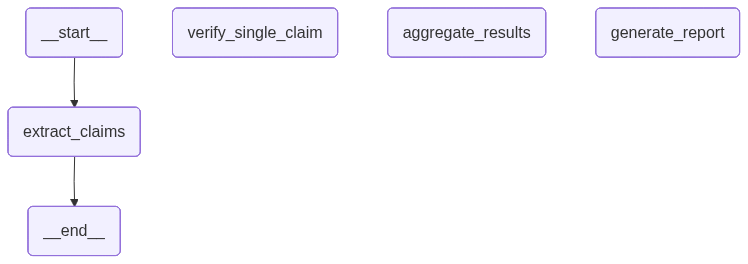

In [13]:
# Visualize the Send API workflow
try:
    from IPython.display import Image, display
    
    print("Send API Workflow Visualization:")
    print("Notice the parallel verify_single_claim nodes\n")
    display(Image(fact_checker_send.get_graph().draw_mermaid_png()))
except Exception as e:
    print(f"Visualization not available: {e}")
    print("\nASCII representation:")
    print(fact_checker_send.get_graph().draw_ascii())

### Test the Send API Approach

Let's test our parallel execution using the Send API.

In [14]:
# Run the fact-checker with Send API approach
initial_state = {
    "article": sample_article,
    "claims": [],
    "verification_results": [],
    "final_report": ""
}

# Measure execution time
start_time = time.time()

# Execute the workflow
result_send = fact_checker_send.invoke(initial_state)

end_time = time.time()
elapsed = end_time - start_time

print(f"\nTotal execution time: {elapsed:.2f} seconds")

# Display the final report
print("\n" + "="*80)
print("FINAL FACT-CHECKING REPORT (Send API Approach)")
print("="*80)
print(result_send["final_report"])

STEP 1: EXTRACTING CLAIMS
Extracting claims from article...
Extracted 8 claims
Ranking claims by verifiability...
Selected top 3 claims for verification
  1. [1.00] OpenAI's latest AI model, GPT-5, has achieved human-level performance on over 95...
  2. [1.00] The new model represents a 300% improvement over OpenAI's previous model....
  3. [1.00] The new model was trained on a dataset containing 10 trillion tokens....

STEP 2: ROUTING CLAIMS FOR PARALLEL VERIFICATION (Send API)
Creating 3 parallel Send operations...

[Claim 1] Starting verification: OpenAI's latest AI model, GPT-5, has achieved human-level pe...
  Searching for sources to verify: OpenAI's latest AI model, GPT-5, has achieved human-level performance on over 95...
[Claim 2] Starting verification: The new model represents a 300% improvement over OpenAI's pr...
  Searching for sources to verify: The new model represents a 300% improvement over OpenAI's previous model....
[Claim 3] Starting verification: The new model was 